# YOLO11n, YOLO26l and RT-DETR-L Evaluation (same protocol as RF-DETR-M)

## Section 1: Install

In [7]:
!pip install -q -U ultralytics supervision requests


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Section 2: Imports

In [8]:
import os
import json
import time
import shutil
import pickle
import asyncio
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import yaml
import torch
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import supervision as sv
from supervision.metrics import MeanAveragePrecision, Precision, Recall, AveragingMethod
from ultralytics import YOLO, RTDETR

COLAB = Path('/content').exists()
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

GPU: NVIDIA GeForce RTX 3070


## Section 3: Settings

In [9]:
OWNER, PROJECT = 'nivetha-udayakumar', 'isy5001g14wildlens'
API = 'https://platform.ultralytics.com/api'

# if COLAB:
#     from google.colab import userdata, files, drive
#     os.environ['ULTRALYTICS_API_KEY'] = userdata.get('ULTRALYTICS_API_KEY')
#     drive.mount('/content/drive')
#     ROOT = Path('/content/drive/MyDrive/WildLens_TRAINING/eval_all_runs')
#     pass
# else:
#     ROOT = Path('eval_all_runs')
ROOT = Path('YOLO_RTDETR_All_Runs_Evaluation')
API_KEY = "ul_446070490b05ee94b6904511697cde5756b97221"
assert API_KEY, 'Set ULTRALYTICS_API_KEY (Colab Secrets or environment variable).'
HEADERS = {'Authorization': f'Bearer {API_KEY}'}

WEIGHTS_DIR, CACHE_DIR, RESULTS_DIR = ROOT / 'weights', ROOT / 'cache', ROOT / 'results'
for d in [WEIGHTS_DIR, CACHE_DIR, RESULTS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

IMGSZ = 640
CONFS = [0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.60, 0.70, 0.80, 0.90]
SPLITS = ['val', 'test']

## Section 4: List Models in the Ultralytics Project

In [10]:
r = requests.get(f'{API}/models/{OWNER}/{PROJECT}', headers=HEADERS, params={'limit': 100})
r.raise_for_status()
payload = r.json()
items = payload if isinstance(payload, list) else next(v for v in payload.values() if isinstance(v, list))
SLUGS = [m.get('slug') or m.get('name') or m.get('id') for m in items]
print(len(SLUGS), 'models:'); print('\n'.join(SLUGS))

19 models:
yl1
yolo26l
yl2
rtdetr-lflip50rot10p0mosaic100
rtdetr-lflip50rot10p0mosaic0
rtdetr-lflip50rot0p0mosaic100
rtdetr-lflip50rot0p0mosaic0
rtdetr-lflip0rot10p0mosaic100
rtdetr-lflip0rot10p0mosaic0
rtdetr-lflip0rot0p0mosaic100
rtdetr-lflip0rot0p0mosaic0
yolo11nflip50rot10p0mosaic100
yolo11nflip50rot10p0mosaic0
yolo11nflip50rot0p0mosaic100
yolo11nflip50rot0p0mosaic0
yolo11nflip0rot10p0mosaic100
yolo11nflip0rot10p0mosaic0
yolo11nflip0rot0p0mosaic100
yolo11nflip0rot0p0mosaic0


## Section 5: Runs to Evaluate

In [11]:
# detector of each model, from its name; edit EXCLUDE / LABELS if needed
def detector_of(slug):
    s = slug.lower().replace('-', '').replace('_', '')
    if 'rtdetr' in s: return 'RT-DETR-L'
    if 'yolo26' in s: return 'YOLO26l'
    if 'yolo11' in s: return 'YOLO11n'
    return None

EXCLUDE = []  # model slugs to skip (e.g. test runs)
LABELS = {}   # optional: {'model-slug': 'Y6'} so tables use the report's run IDs

RUNS = {s: detector_of(s) for s in SLUGS if detector_of(s) and s not in EXCLUDE}
display(pd.DataFrame({'Model': list(RUNS), 'Detector': list(RUNS.values()),
                      'Run ID': [LABELS.get(s, s) for s in RUNS]}))

,Model,Detector,Run ID
0,yolo26l,YOLO26l,yolo26l
1,rtdetr-lflip50rot10p0mosaic100,RT-DETR-L,rtdetr-lflip50rot10p0mosaic100
2,rtdetr-lflip50rot10p0mosaic0,RT-DETR-L,rtdetr-lflip50rot10p0mosaic0
3,rtdetr-lflip50rot0p0mosaic100,RT-DETR-L,rtdetr-lflip50rot0p0mosaic100
4,rtdetr-lflip50rot0p0mosaic0,RT-DETR-L,rtdetr-lflip50rot0p0mosaic0
5,rtdetr-lflip0rot10p0mosaic100,RT-DETR-L,rtdetr-lflip0rot10p0mosaic100
6,rtdetr-lflip0rot10p0mosaic0,RT-DETR-L,rtdetr-lflip0rot10p0mosaic0
7,rtdetr-lflip0rot0p0mosaic100,RT-DETR-L,rtdetr-lflip0rot0p0mosaic100
8,rtdetr-lflip0rot0p0mosaic0,RT-DETR-L,rtdetr-lflip0rot0p0mosaic0
9,yolo11nflip50rot10p0mosaic100,YOLO11n,yolo11nflip50rot10p0mosaic100


## Section 6: Download Weights

In [12]:
for slug in RUNS:
    out = WEIGHTS_DIR / f'{slug}.pt'
    if out.exists():
        continue
    r = requests.get(f'{API}/models/{OWNER}/{PROJECT}/{slug}/files', headers=HEADERS); r.raise_for_status()
    pt = next(f for f in r.json()['files'] if f['name'].endswith('.pt'))
    with requests.get(pt['downloadUrl'], stream=True) as d:
        d.raise_for_status()
        with open(out, 'wb') as f:
            shutil.copyfileobj(d.raw, f)
    print('Downloaded', out.name, f"{out.stat().st_size / 1e6:.1f} MB")

Downloaded yolo26l.pt 53.0 MB
Downloaded rtdetr-lflip50rot10p0mosaic100.pt 66.2 MB
Downloaded rtdetr-lflip50rot10p0mosaic0.pt 66.2 MB
Downloaded rtdetr-lflip50rot0p0mosaic100.pt 66.2 MB
Downloaded rtdetr-lflip50rot0p0mosaic0.pt 66.2 MB
Downloaded rtdetr-lflip0rot10p0mosaic100.pt 66.2 MB
Downloaded rtdetr-lflip0rot10p0mosaic0.pt 66.2 MB
Downloaded rtdetr-lflip0rot0p0mosaic100.pt 66.2 MB
Downloaded rtdetr-lflip0rot0p0mosaic0.pt 66.2 MB
Downloaded yolo11nflip50rot10p0mosaic100.pt 5.5 MB
Downloaded yolo11nflip50rot10p0mosaic0.pt 5.5 MB
Downloaded yolo11nflip50rot0p0mosaic100.pt 5.5 MB
Downloaded yolo11nflip50rot0p0mosaic0.pt 5.5 MB
Downloaded yolo11nflip0rot10p0mosaic100.pt 5.5 MB
Downloaded yolo11nflip0rot10p0mosaic0.pt 5.5 MB
Downloaded yolo11nflip0rot0p0mosaic100.pt 5.5 MB
Downloaded yolo11nflip0rot0p0mosaic0.pt 5.5 MB


## Section 7: Dataset

In [13]:
# Option A: a local YOLO dataset folder (images/ and labels/ with val and test)
DATA_YAML = Path('../../data/wildlife_dataset/wildlife_dataset.yaml')

# Option B: a freshly exported .ndjson from Ultralytics Platform (old image links expire)
if not DATA_YAML.exists():
    from ultralytics.data.converter import convert_ndjson_to_yolo
    if COLAB:
        uploaded = files.upload()
        NDJSON = os.path.abspath(next(n for n in uploaded if n.lower().endswith('.ndjson')))
    else:
        NDJSON = os.path.abspath('isy5002-g14-dataset.ndjson')
    with ThreadPoolExecutor(max_workers=1) as ex:
        DATA_YAML = Path(str(ex.submit(lambda: asyncio.run(convert_ndjson_to_yolo(NDJSON, output_path=str(ROOT / 'dataset')))).result()))

cfg = yaml.safe_load(open(DATA_YAML))
DATASET_DIR = Path(cfg.get('path') or DATA_YAML.parent)
if not DATASET_DIR.is_absolute() or not DATASET_DIR.exists():
    DATASET_DIR = DATA_YAML.parent
names = cfg['names']
CLASS_NAMES = [names[i] for i in sorted(names)] if isinstance(names, dict) else list(names)

datasets = {split: sv.DetectionDataset.from_yolo(
    images_directory_path=str(DATASET_DIR / 'images' / split),
    annotations_directory_path=str(DATASET_DIR / 'labels' / split),
    data_yaml_path=str(DATA_YAML)) for split in SPLITS}
print(DATASET_DIR, CLASS_NAMES, {s: len(d) for s, d in datasets.items()})

C:\Users\zheng\Documents\ISY5002-PRS-G14\data\wildlife_dataset ['buffalo', 'elephant', 'rhino', 'zebra', 'okapi', 'leopard', 'cheetah'] {'val': 332, 'test': 331}


## Section 8: Predict All Runs (threshold 0.01, cached)

In [14]:
def load(slug):
    cls = RTDETR if RUNS[slug] == 'RT-DETR-L' else YOLO
    return cls(str(WEIGHTS_DIR / f'{slug}.pt'))

preds = {}
for slug in RUNS:
    cache = CACHE_DIR / f'{slug}.pkl'
    if cache.exists():
        preds[slug] = pickle.load(open(cache, 'rb')); continue
    model, out = load(slug), {}
    for split in SPLITS:
        p, t = [], []
        for image_path, _, annotations in datasets[split]:
            p.append(sv.Detections.from_ultralytics(model.predict(image_path, imgsz=IMGSZ, conf=0.01, verbose=False)[0]))
            t.append(annotations)
        out[split] = (p, t)
    preds[slug] = out
    pickle.dump(out, open(cache, 'wb'))
    print('Predicted', slug)

Predicted yolo26l
Predicted rtdetr-lflip50rot10p0mosaic100
Predicted rtdetr-lflip50rot10p0mosaic0
Predicted rtdetr-lflip50rot0p0mosaic100
Predicted rtdetr-lflip50rot0p0mosaic0
Predicted rtdetr-lflip0rot10p0mosaic100
Predicted rtdetr-lflip0rot10p0mosaic0
Predicted rtdetr-lflip0rot0p0mosaic100
Predicted rtdetr-lflip0rot0p0mosaic0
Predicted yolo11nflip50rot10p0mosaic100
Predicted yolo11nflip50rot10p0mosaic0
Predicted yolo11nflip50rot0p0mosaic100
Predicted yolo11nflip50rot0p0mosaic0
Predicted yolo11nflip0rot10p0mosaic100
Predicted yolo11nflip0rot10p0mosaic0
Predicted yolo11nflip0rot0p0mosaic100
Predicted yolo11nflip0rot0p0mosaic0


## Section 9: Metric Functions (same as RF-DETR notebooks)

In [15]:
N = len(CLASS_NAMES)

def evaluate(predictions, targets):
    map_result = MeanAveragePrecision().update(predictions, targets).compute()
    best = {'F1': -1.0}
    for conf in np.arange(0.05, 0.96, 0.05):
        kept = [p[p.confidence >= conf] for p in predictions]
        precision = Precision(averaging_method=AveragingMethod.MACRO).update(kept, targets).compute().precision_at_50
        recall = Recall(averaging_method=AveragingMethod.MACRO).update(kept, targets).compute().recall_at_50
        f1 = 2 * precision * recall / (precision + recall + 1e-9)
        if f1 > best['F1']:
            best = {'Precision': float(precision), 'Recall': float(recall), 'F1': float(f1), 'Confidence': round(float(conf), 2)}
    return {'mAP50': float(map_result.map50), 'mAP50-95': float(map_result.map50_95), 'mAP75': float(map_result.map75),
            'Best-F1 precision': best['Precision'], 'Best-F1 recall': best['Recall'], 'Best F1': best['F1'],
            'Best-F1 confidence': best['Confidence']}

def per_class_at(predictions, targets, conf):
    # rows = true class, columns = predicted class, last row/column = background
    cm = sv.ConfusionMatrix.from_detections(predictions=predictions, targets=targets, classes=CLASS_NAMES,
                                            conf_threshold=conf, iou_threshold=0.5).matrix.astype(int)
    t = pd.DataFrame({'Class': CLASS_NAMES,
                      'Correct': [cm[c, c] for c in range(N)],
                      'Wrong': [cm[:N, c].sum() - cm[c, c] for c in range(N)],  # predicted as this class, but another animal
                      'FP': [cm[N, c] for c in range(N)],                       # predicted as this class, but no animal there
                      'Missed': [cm[c, N] for c in range(N)]})                  # an animal of this class that was not detected
    t['Op. acc.'] = t.Correct / np.maximum(t.Correct + t.Wrong + t.FP, 1)
    t['Pure acc.'] = t.Correct / np.maximum(t.Correct + t.Wrong, 1)
    return t

def at_conf(predictions, targets, conf):
    t = per_class_at(predictions, targets, conf)
    kept = [p[p.confidence >= conf] for p in predictions]
    m = MeanAveragePrecision().update(kept, targets).compute()
    c, w, fp, mi = t.Correct.sum(), t.Wrong.sum(), t.FP.sum(), t.Missed.sum()
    p, r = c / max(c + w + fp, 1), c / max(c + w + mi, 1)
    return {'Correct': c, 'Wrong': w, 'FP': fp, 'Missed': mi, 'Recall': r, 'Precision': p, 'F1': 2 * p * r / max(p + r, 1e-9),
            'Op. acc. (pooled)': p, 'Op. acc. (mean)': t['Op. acc.'].mean(), 'Pure acc. (pooled)': c / max(c + w, 1),
            'mAP50': float(m.map50), 'mAP50-95': float(m.map50_95)}

## Section 10: Threshold Sweep and Final Threshold for Every Run

In [16]:
sweeps, FINAL = {}, {}
for slug in RUNS:
    rows = [{'Split': split, 'Conf': conf, **at_conf(*preds[slug][split], conf)} for split in SPLITS for conf in CONFS]
    sw = sweeps[slug] = pd.DataFrame(rows)
    v = sw[sw.Split == 'val'].sort_values('Conf')
    r0 = v.Recall.iloc[0] * 100
    # Final threshold: highest conf whose val recall is within 2 points of the recall at conf 0.25
    FINAL[slug] = float(v.Conf[v.Recall * 100 >= r0 - 2].max())
    sw.to_csv(RESULTS_DIR / f'sweep_{slug}.csv', index=False)
print(pd.Series(FINAL, name='Final conf'))

yolo26l                           0.50
rtdetr-lflip50rot10p0mosaic100    0.40
rtdetr-lflip50rot10p0mosaic0      0.30
rtdetr-lflip50rot0p0mosaic100     0.60
rtdetr-lflip50rot0p0mosaic0       0.35
rtdetr-lflip0rot10p0mosaic100     0.30
rtdetr-lflip0rot10p0mosaic0       0.50
rtdetr-lflip0rot0p0mosaic100      0.45
rtdetr-lflip0rot0p0mosaic0        0.40
yolo11nflip50rot10p0mosaic100     0.40
yolo11nflip50rot10p0mosaic0       0.40
yolo11nflip50rot0p0mosaic100      0.40
yolo11nflip50rot0p0mosaic0        0.45
yolo11nflip0rot10p0mosaic100      0.40
yolo11nflip0rot10p0mosaic0        0.50
yolo11nflip0rot0p0mosaic100       0.40
yolo11nflip0rot0p0mosaic0         0.45
Name: Final conf, dtype: float64


## Section 11: Run Comparison on Validation (one table per detector)

In [17]:
run_rows = []
for slug, det in RUNS.items():
    v = sweeps[slug]; v = v[(v.Split == 'val') & (v.Conf == FINAL[slug])].iloc[0]
    run_rows.append({'Detector': det, 'Run': LABELS.get(slug, slug), 'Model': slug, 'Final conf': FINAL[slug],
                     'mAP50': v.mAP50, 'mAP50-95': v['mAP50-95'], 'Op. acc.': v['Op. acc. (pooled)'],
                     'Pure acc.': v['Pure acc. (pooled)'], 'F1': v.F1, 'Recall': v.Recall})
runs_df = pd.DataFrame(run_rows).sort_values(['Detector', 'mAP50-95'], ascending=[True, False])
runs_df.to_csv(RESULTS_DIR / 'run_comparison_val.csv', index=False)

BEST = {}
for det, g in runs_df.groupby('Detector'):
    top = g[g['mAP50-95'] >= g['mAP50-95'].max() - 0.005]   # within 0.005 = tied
    BEST[det] = top.sort_values('Op. acc.', ascending=False).Model.iloc[0]  # tie broken by operational accuracy
    print(f'\n{det} (validation, each run at its final conf); best: {LABELS.get(BEST[det], BEST[det])}')
    display(g.drop(columns=['Detector', 'Model']).style.format(
        {c: '{:.1%}' for c in ['mAP50', 'mAP50-95', 'Op. acc.', 'Pure acc.', 'Recall']} | {'F1': '{:.3f}', 'Final conf': '{:.2f}'}))


RT-DETR-L (validation, each run at its final conf); best: rtdetr-lflip50rot0p0mosaic100


,Run,Final conf,mAP50,mAP50-95,Op. acc.,Pure acc.,F1,Recall
3,rtdetr-lflip50rot0p0mosaic100,0.60,93.4%,77.3%,92.1%,99.5%,0.932,94.3%
4,rtdetr-lflip50rot0p0mosaic0,0.35,94.2%,74.4%,84.6%,100.0%,0.896,95.2%
8,rtdetr-lflip0rot0p0mosaic0,0.40,92.9%,73.6%,86.3%,99.3%,0.899,93.9%
7,rtdetr-lflip0rot0p0mosaic100,0.45,91.9%,73.4%,87.0%,99.5%,0.901,93.4%
6,rtdetr-lflip0rot10p0mosaic0,0.50,91.6%,70.1%,93.6%,99.3%,0.934,93.2%
2,rtdetr-lflip50rot10p0mosaic0,0.30,90.7%,69.9%,84.8%,98.8%,0.886,92.8%
5,rtdetr-lflip0rot10p0mosaic100,0.30,88.5%,65.5%,64.0%,99.3%,0.757,92.6%
1,rtdetr-lflip50rot10p0mosaic100,0.40,88.0%,55.4%,65.7%,99.1%,0.765,91.5%



YOLO11n (validation, each run at its final conf); best: yolo11nflip50rot0p0mosaic0


,Run,Final conf,mAP50,mAP50-95,Op. acc.,Pure acc.,F1,Recall
12,yolo11nflip50rot0p0mosaic0,0.45,91.2%,74.8%,94.2%,99.3%,0.930,91.9%
11,yolo11nflip50rot0p0mosaic100,0.40,92.1%,73.5%,92.2%,99.5%,0.925,92.8%
13,yolo11nflip0rot10p0mosaic100,0.40,90.2%,72.3%,90.7%,98.6%,0.912,91.7%
16,yolo11nflip0rot0p0mosaic0,0.45,89.7%,71.8%,89.8%,98.8%,0.904,91.0%
15,yolo11nflip0rot0p0mosaic100,0.40,89.8%,71.4%,91.4%,99.0%,0.912,91.0%
10,yolo11nflip50rot10p0mosaic0,0.40,92.1%,71.2%,92.8%,99.5%,0.929,93.0%
14,yolo11nflip0rot10p0mosaic0,0.50,91.2%,71.0%,94.4%,99.5%,0.929,91.5%
9,yolo11nflip50rot10p0mosaic100,0.40,88.2%,67.0%,91.1%,98.6%,0.902,89.3%



YOLO26l (validation, each run at its final conf); best: yolo26l


,Run,Final conf,mAP50,mAP50-95,Op. acc.,Pure acc.,F1,Recall
0,yolo26l,0.50,93.3%,76.9%,96.2%,99.8%,0.949,93.7%


## Section 12: Best Run: Validation vs Test

In [18]:
for det, slug in BEST.items():
    cols = {}
    for split in SPLITS:
        s = at_conf(*preds[slug][split], FINAL[slug]); std = evaluate(*preds[slug][split])
        cols['Validation' if split == 'val' else 'Test'] = {
            'mAP50 (t = 0.01)': f"{std['mAP50']:.1%}", 'mAP50-95 (t = 0.01)': f"{std['mAP50-95']:.1%}",
            f'mAP50 (t = {FINAL[slug]:.2f})': f"{s['mAP50']:.1%}", f'mAP50-95 (t = {FINAL[slug]:.2f})': f"{s['mAP50-95']:.1%}",
            'Recall': f"{s['Recall']:.1%}", 'Precision': f"{s['Precision']:.1%}", 'F1': f"{s['F1']:.3f}",
            'Operational accuracy': f"{s['Op. acc. (pooled)']:.1%}", 'Pure species accuracy': f"{s['Pure acc. (pooled)']:.1%}",
            'Correct / Wrong / FP / Missed': f"{s['Correct']} / {s['Wrong']} / {s['FP']} / {s['Missed']}"}
    vt = pd.DataFrame(cols); vt.to_csv(RESULTS_DIR / f'{det}_val_vs_test.csv')
    print(f'\n{det}: {LABELS.get(slug, slug)} at t = {FINAL[slug]:.2f}'); display(vt)


RT-DETR-L: rtdetr-lflip50rot0p0mosaic100 at t = 0.60


,Validation,Test
mAP50 (t = 0.01),96.7%,96.6%
mAP50-95 (t = 0.01),79.5%,77.4%
mAP50 (t = 0.60),93.4%,94.1%
mAP50-95 (t = 0.60),77.3%,75.1%
Recall,94.3%,94.3%
Precision,92.1%,92.2%
F1,0.932,0.932
Operational accuracy,92.1%,92.2%
Pure species accuracy,99.5%,99.8%
Correct / Wrong / FP / Missed,431 / 2 / 35 / 24,447 / 1 / 37 / 26



YOLO11n: yolo11nflip50rot0p0mosaic0 at t = 0.45


,Validation,Test
mAP50 (t = 0.01),95.5%,93.8%
mAP50-95 (t = 0.01),77.4%,75.1%
mAP50 (t = 0.45),91.2%,90.3%
mAP50-95 (t = 0.45),74.8%,72.6%
Recall,91.9%,91.4%
Precision,94.2%,91.7%
F1,0.930,0.915
Operational accuracy,94.2%,91.7%
Pure species accuracy,99.3%,98.9%
Correct / Wrong / FP / Missed,420 / 3 / 23 / 34,433 / 5 / 34 / 36



YOLO26l: yolo26l at t = 0.50


,Validation,Test
mAP50 (t = 0.01),95.8%,94.7%
mAP50-95 (t = 0.01),78.6%,77.3%
mAP50 (t = 0.50),93.3%,92.8%
mAP50-95 (t = 0.50),76.9%,75.8%
Recall,93.7%,93.9%
Precision,96.2%,93.5%
F1,0.949,0.937
Operational accuracy,96.2%,93.5%
Pure species accuracy,99.8%,99.1%
Correct / Wrong / FP / Missed,428 / 1 / 16 / 28,445 / 4 / 27 / 25


## Section 13: Best Run: Per-class Test Results

In [19]:
for det, slug in BEST.items():
    t = per_class_at(*preds[slug]['test'], FINAL[slug])
    tot = t[['Correct', 'Wrong', 'FP', 'Missed']].sum()
    t.loc[len(t)] = ['Total', *tot.values, tot.Correct / (tot.Correct + tot.Wrong + tot.FP), tot.Correct / (tot.Correct + tot.Wrong)]
    t.to_csv(RESULTS_DIR / f'{det}_per_class_test.csv', index=False)
    print(f'\n{det} per-class test (t = {FINAL[slug]:.2f})')
    display(t.style.format({'Op. acc.': '{:.1%}', 'Pure acc.': '{:.1%}'}))


RT-DETR-L per-class test (t = 0.60)


,Class,Correct,Wrong,FP,Missed,Op. acc.,Pure acc.
0,buffalo,54,0,7,6,88.5%,100.0%
1,elephant,66,0,10,9,86.8%,100.0%
2,rhino,43,0,0,0,100.0%,100.0%
3,zebra,76,0,13,4,85.4%,100.0%
4,okapi,78,0,4,4,95.1%,100.0%
5,leopard,61,0,1,1,98.4%,100.0%
6,cheetah,69,1,2,2,95.8%,98.6%
7,Total,447,1,37,26,92.2%,99.8%



YOLO11n per-class test (t = 0.45)


,Class,Correct,Wrong,FP,Missed,Op. acc.,Pure acc.
0,buffalo,54,0,3,5,94.7%,100.0%
1,elephant,65,2,13,10,81.2%,97.0%
2,rhino,40,0,2,2,95.2%,100.0%
3,zebra,75,0,8,5,90.4%,100.0%
4,okapi,76,0,2,5,97.4%,100.0%
5,leopard,59,1,3,3,93.7%,98.3%
6,cheetah,64,2,3,6,92.8%,97.0%
7,Total,433,5,34,36,91.7%,98.9%



YOLO26l per-class test (t = 0.50)


,Class,Correct,Wrong,FP,Missed,Op. acc.,Pure acc.
0,buffalo,51,0,4,7,92.7%,100.0%
1,elephant,67,2,10,8,84.8%,97.1%
2,rhino,41,0,0,2,100.0%,100.0%
3,zebra,79,0,12,1,86.8%,100.0%
4,okapi,79,0,0,2,100.0%,100.0%
5,leopard,61,0,0,1,100.0%,100.0%
6,cheetah,67,2,1,4,95.7%,97.1%
7,Total,445,4,27,25,93.5%,99.1%


## Section 14: Best Run: Threshold Sweep Table and Figure


RT-DETR-L threshold sweep (validation)


,Conf,Correct,FP,Missed,Recall,Op. acc. (pooled),F1
0,0.25,437,146,18,95.6%,74.7%,0.839
1,0.30,435,106,21,95.2%,80.3%,0.871
2,0.35,435,82,21,95.2%,84.0%,0.892
3,0.40,435,63,21,95.2%,87.2%,0.910
4,0.45,434,55,22,95.0%,88.6%,0.917
5,0.50,434,44,22,95.0%,90.6%,0.927
6,0.60,431,35,24,94.3%,92.1%,0.932
7,0.70,425,23,29,93.0%,94.2%,0.936
8,0.80,418,13,37,91.5%,96.5%,0.939
9,0.90,359,1,98,78.6%,99.7%,0.879


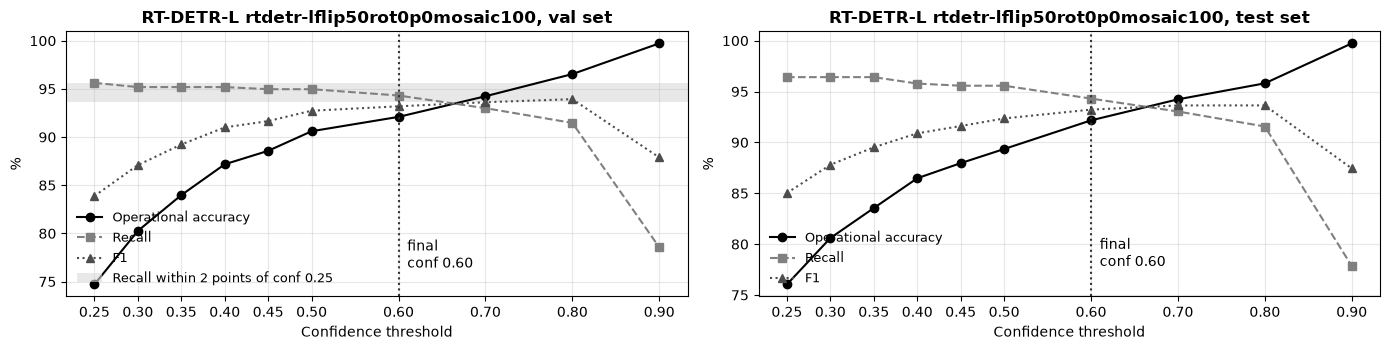


YOLO11n threshold sweep (validation)


,Conf,Correct,FP,Missed,Recall,Op. acc. (pooled),F1
0,0.25,426,45,27,93.2%,89.7%,0.914
1,0.30,426,43,27,93.2%,90.1%,0.916
2,0.35,424,35,29,92.8%,91.6%,0.922
3,0.40,421,31,32,92.1%,92.3%,0.922
4,0.45,420,23,34,91.9%,94.2%,0.930
5,0.50,416,20,38,91.0%,94.8%,0.929
6,0.60,411,14,44,89.9%,96.3%,0.930
7,0.70,408,12,47,89.3%,96.7%,0.928
8,0.80,385,6,70,84.2%,98.0%,0.906
9,0.90,237,0,220,51.9%,100.0%,0.683


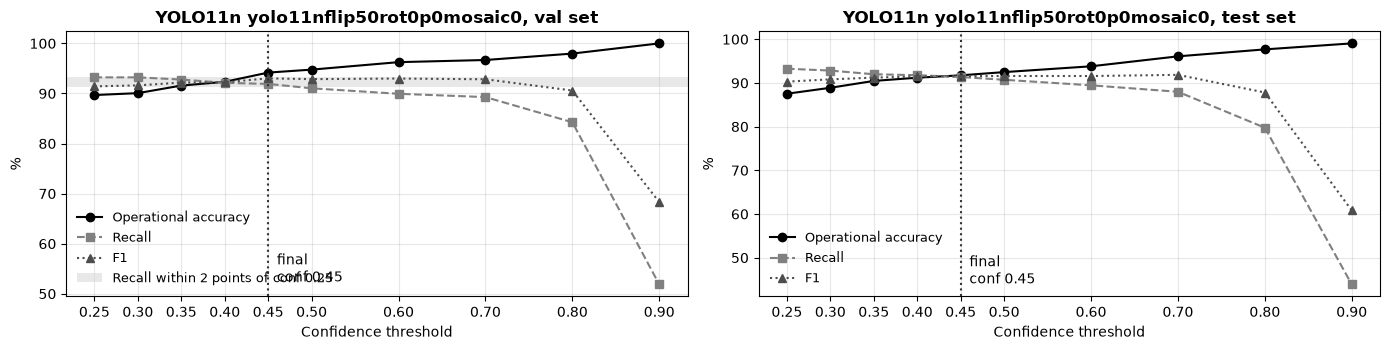


YOLO26l threshold sweep (validation)


,Conf,Correct,FP,Missed,Recall,Op. acc. (pooled),F1
0,0.25,434,33,22,95.0%,92.7%,0.938
1,0.30,434,29,22,95.0%,93.5%,0.942
2,0.35,433,25,23,94.7%,94.3%,0.945
3,0.40,431,22,25,94.3%,94.9%,0.946
4,0.45,429,19,27,93.9%,95.5%,0.947
5,0.50,428,16,28,93.7%,96.2%,0.949
6,0.60,423,11,33,92.6%,97.2%,0.948
7,0.70,412,9,45,90.2%,97.9%,0.938
8,0.80,394,7,63,86.2%,98.3%,0.918
9,0.90,300,0,157,65.6%,100.0%,0.793


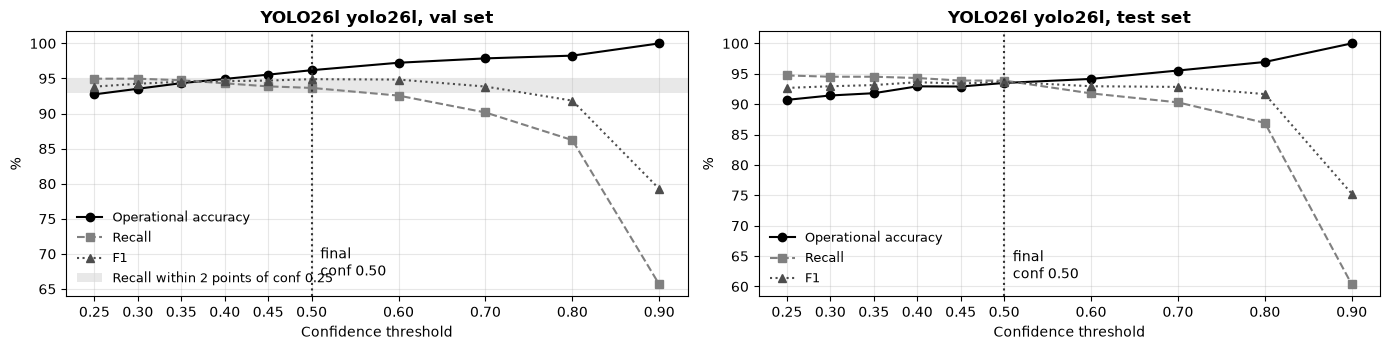

In [20]:
for det, slug in BEST.items():
    sw = sweeps[slug]; v = sw[sw.Split == 'val'].sort_values('Conf'); r0 = v.Recall.iloc[0] * 100
    print(f'\n{det} threshold sweep (validation)')
    display(v[['Conf', 'Correct', 'FP', 'Missed', 'Recall', 'Op. acc. (pooled)', 'F1']].style.format(
        {'Recall': '{:.1%}', 'Op. acc. (pooled)': '{:.1%}', 'F1': '{:.3f}', 'Conf': '{:.2f}'}))
    fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
    for ax, split in zip(axes, SPLITS):
        d = sw[sw.Split == split].sort_values('Conf')
        ax.plot(d.Conf, d['Op. acc. (pooled)'] * 100, 'k-o', label='Operational accuracy')
        ax.plot(d.Conf, d.Recall * 100, '--s', color='0.5', label='Recall')
        ax.plot(d.Conf, d.F1 * 100, ':^', color='0.3', label='F1')
        if split == 'val':
            ax.axhspan(r0 - 2, r0, color='0.85', alpha=0.6, lw=0, label='Recall within 2 points of conf 0.25')
        ax.axvline(FINAL[slug], color='0.2', ls=':', lw=1.5)
        ax.text(FINAL[slug] + 0.01, ax.get_ylim()[0] + 3, f'final\nconf {FINAL[slug]:.2f}', fontsize=10)
        ax.set_xticks(CONFS); ax.set_xlabel('Confidence threshold'); ax.set_ylabel('%'); ax.grid(alpha=0.3)
        ax.set_title(f'{det} {LABELS.get(slug, slug)}, {split} set', fontweight='bold'); ax.legend(loc='lower left', fontsize=9, frameon=False)
    plt.tight_layout(); plt.savefig(RESULTS_DIR / f'{det}_threshold_sweep.png', dpi=200); plt.show()

## Section 15: Best Run: Inference Time

In [21]:
GPU = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'
paths, MS = datasets['test'].image_paths, {}
for det, slug in BEST.items():
    model = load(slug)
    for p in paths[:10]:
        model.predict(p, imgsz=IMGSZ, conf=FINAL[slug], verbose=False)  # warm-up
    times = []
    for p in paths:
        if torch.cuda.is_available(): torch.cuda.synchronize()
        start = time.perf_counter()
        model.predict(p, imgsz=IMGSZ, conf=FINAL[slug], verbose=False)
        if torch.cuda.is_available(): torch.cuda.synchronize()
        times.append((time.perf_counter() - start) * 1000)
    MS[det] = float(np.mean(times)); print(f'{det}: {MS[det]:.1f} ms/image ({GPU})')

RT-DETR-L: 33.0 ms/image (NVIDIA GeForce RTX 3070)
YOLO11n: 24.4 ms/image (NVIDIA GeForce RTX 3070)
YOLO26l: 36.1 ms/image (NVIDIA GeForce RTX 3070)


## Section 16: Final Deployment Settings

In [22]:
rows = []
for det, slug in BEST.items():
    s = at_conf(*preds[slug]['test'], FINAL[slug]); std = evaluate(*preds[slug]['test'])
    rows.append({'Detector': det, 'Best run': LABELS.get(slug, slug), 'Weights': f'{slug}.pt', 'Confidence threshold': FINAL[slug],
                 'Test mAP50-95 (t = 0.01)': round(std['mAP50-95'], 4), 'Test recall': round(s['Recall'], 4),
                 'Test precision': round(s['Precision'], 4), 'Test F1': round(s['F1'], 4),
                 'Test op. acc.': round(s['Op. acc. (pooled)'], 4), 'FP': s['FP'], 'Missed': s['Missed'],
                 'ms/image': round(MS[det], 1), 'GPU': GPU})
deploy = pd.DataFrame(rows); deploy.to_csv(RESULTS_DIR / 'final_deployment_settings.csv', index=False)
display(deploy)

,Detector,Best run,Weights,Confidence threshold,Test mAP50-95 (t = 0.01),Test recall,Test precision,Test F1,Test op. acc.,FP,Missed,ms/image,GPU
0,RT-DETR-L,rtdetr-lflip50rot0p0mosaic100,rtdetr-lflip50rot0p0mosaic100.pt,0.60,0.7742,0.9430,0.9216,0.9322,0.9216,37,26,33.0,NVIDIA GeForce RTX 3070
1,YOLO11n,yolo11nflip50rot0p0mosaic0,yolo11nflip50rot0p0mosaic0.pt,0.45,0.7512,0.9135,0.9174,0.9154,0.9174,34,36,24.4,NVIDIA GeForce RTX 3070
2,YOLO26l,yolo26l,yolo26l.pt,0.50,0.7733,0.9388,0.9349,0.9368,0.9349,27,25,36.1,NVIDIA GeForce RTX 3070


## Section 17: Zip Results

In [23]:
archive = shutil.make_archive(str(ROOT / 'eval_all_runs_results'), 'zip', RESULTS_DIR)
print('Zip:', archive)
if COLAB:
    files.download(archive)

Zip: c:\Users\zheng\Documents\ISY5002-PRS-G14\ai-applications\vs_notebooks\YOLO_RTDETR_All_Runs_Evaluation\eval_all_runs_results.zip


NameError: name 'files' is not defined